# Ridge regression

Linear regression on log price with an L2 penalty `alpha · Σ bᵢ²`. The penalty shrinks the coefficients of
rare categories (a commune with 6 listings) towards 0 instead of letting them fit noise. `alpha` is picked on
the **validation split** (lowest RMSE on log price), then the model is refit on train, the same role val plays
in the NN's early stopping.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

LAB = Path.cwd()
while not (LAB / "engines").is_dir():  # notebook lives in laboratory/engines/<model>/
    LAB = LAB.parent
sys.path.insert(0, str(LAB))
from engines.common import compare_table, load_config, load_splits, run_seeds

cfg = load_config()  # configs/neural_network_config.yml: same data split, seeds and features as the NN
SEEDS = cfg["data"].get("seeds") or [cfg["data"]["seed"]]
TARGET = cfg["data"]["target"]
FC = cfg["features"]
OUT = LAB / "models" / "ridge_regression"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
print("seeds", SEEDS, "->", OUT)

seeds [42, 7, 13, 21, 99] -> C:\Projects\CADT\property-valuation-model\laboratory\models\ridge_regression


## Features
Same columns as the NN (`features` in the config):
- **categorical** → one-hot. Values seen fewer than `min_count` times in train, and unseen ones, share one
  "infrequent" column (like the NN's id 0).
- **numeric** → `log1p` for the `features.log` columns, then standardized (fit on train only).
- **binary** flags → 0/1 as is.
- `interact=True` adds property type × numeric columns, so a m² of land and a m² of condo get their own slope.

Target = **log price**, like the NN: prices go from $5k to $20M and errors scale with price, so a fit on raw
dollars would be driven by a few mansions. Coefficients then read as % effects.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TYPES = ["Condo", "Flat", "House", "Land", "Link House", "Shophouse", "Twin Villa", "Villa"]

def prep(df, interact=False):
    """Model-ready frame: cleaned categoricals, logged numerics, 0/1 flags; optional type x numeric columns."""
    x = pd.DataFrame(index=df.index)
    for c in FC["categorical"]:
        x[c] = df[c].astype("string").fillna("Unknown").str.strip()
    x["commune"] = x["district"] + "|" + x["commune"]  # commune names repeat across districts
    for c in FC["numeric"]:
        v = df[c].astype(float).clip(lower=0)
        x[c] = np.log1p(v) if c in FC.get("log", []) else v
    for c in FC["binary"]:
        x[c] = df[c].astype(float)
    if interact:
        for t in TYPES:
            is_t = (df["property_type"] == t).astype(float)
            for c in FC["numeric"]:
                x[f"{c}*{t}"] = x[c] * is_t
    return x

def encoder(x):
    """One-hot (rare / unseen -> shared 'infrequent' column), standardize numerics, pass flags through."""
    nums = [c for c in x.columns if c not in FC["categorical"] and c not in FC["binary"]]
    return ColumnTransformer([
        ("cat", OneHotEncoder(min_frequency=FC["min_count"], handle_unknown="infrequent_if_exist"), FC["categorical"]),
        ("num", StandardScaler(), nums),
        ("bin", "passthrough", FC["binary"]),
    ])

def effects(pipe):
    """% price change when a flag is on / for each property type vs the rest, all else equal: exp(coef) - 1."""
    coef = pd.Series(pipe[-1].coef_, index=pipe[0].get_feature_names_out())
    keep = coef[coef.index.str.startswith(("bin__", "cat__property_type_"))]
    keep.index = keep.index.str.replace("bin__", "").str.replace("cat__property_type_", "type: ")
    return (np.exp(keep) - 1).mul(100).sort_values()

def plot_effects(eff, title):
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(eff) + 1))
    ax.barh(eff.index, eff, color=SERIES[0], height=0.6)
    ax.axvline(0, color=AXIS, lw=1)
    ax.grid(axis="y", visible=False)
    span = eff.abs().max()
    for y, v in enumerate(eff):
        ax.text(v + (0.02 if v >= 0 else -0.02) * span, y, f"{v:+.0f}%", va="center",
                ha="left" if v >= 0 else "right", color=INK2, fontsize=9)
    ax.set_xlabel("price change, all else equal (%)")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

prep(load_splits(cfg["data"]["path"], seed=SEEDS[0])[0]).head(3)  # what the model sees

,property_type,province,district,commune,borey_name,title_deed,area_m2,land_width_m,land_length_m,floor_level,...,has_lift,has_parking,has_pool,has_sauna,on_main_road,area_m2_missing,bedrooms_missing,bathrooms_missing,floor_level_missing,land_dims_missing
0,Condo,Phnom Penh,Tuol Kouk,Tuol Kouk|Boeng Kak 1,Time Square,Strata Title,4.615121,0.000000,0.000000,26.0,...,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,Link House,Phnom Penh,Chroy Changvar,Chroy Changvar|Preaek Lieb,Peng Huoth,Unknown,4.584967,1.808289,3.044522,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,Condo,Phnom Penh,Chbar Ampov,Chbar Ampov|Nirouth,No Borey,Unknown,4.753590,0.000000,0.000000,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0


## Model

In [3]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

ALPHAS = np.logspace(-2, 3, 11)

def fit(train, val, cfg, interact=False):
    """Pick alpha on val, refit on train. Returns predict(df) -> log price."""
    xt, xv = prep(train, interact), prep(val, interact)
    yt, yv = np.log(train[TARGET]), np.log(val[TARGET])
    val_rmse = {}
    for a in ALPHAS:
        p = make_pipeline(encoder(xt), Ridge(alpha=a)).fit(xt, yt)
        val_rmse[float(a)] = float(np.sqrt(np.mean((p.predict(xv) - yv) ** 2)))
    alpha = min(val_rmse, key=val_rmse.get)
    pipe = make_pipeline(encoder(xt), Ridge(alpha=alpha)).fit(xt, yt)
    predict = lambda df: pipe.predict(prep(df, interact))
    predict.pipe, predict.alpha, predict.val_rmse = pipe, alpha, val_rmse
    return predict

## Train on every seed, score, save
`run_seeds` (in `engines/common.py`) does the same as the NN's `train.py`: for each seed it makes the same
train/val/test split, calls `fit`, scores with `regression_metrics` and writes

```
models/ridge_regression/<name>/seed_<s>/metrics.json, test_predictions.csv
models/ridge_regression/<name>/summary.json          mean / std over seeds
```

In [4]:
RUNS = ["base", "interact"]
summary, fitted = run_seeds(fit, cfg, OUT / "base")
print("with type x numeric interactions")
summary_i, fitted_i = run_seeds(lambda tr, va, c: fit(tr, va, c, interact=True), cfg, OUT / "interact")
for name, f in (("base", fitted), ("interact", fitted_i)):
    print(f"{name:<9} alpha per seed: {[round(p.alpha, 2) for p in f]}")

[seed 42] test MdAPE 26.7%  RMSE log 0.480  R2 0.677


[seed 7] test MdAPE 26.7%  RMSE log 0.476  R2 0.731


[seed 13] test MdAPE 26.5%  RMSE log 0.470  R2 0.684


[seed 21] test MdAPE 26.2%  RMSE log 0.469  R2 0.665


[seed 99] test MdAPE 27.6%  RMSE log 0.480  R2 0.712
with type x numeric interactions


[seed 42] test MdAPE 26.4%  RMSE log 0.472  R2 0.698


[seed 7] test MdAPE 26.0%  RMSE log 0.469  R2 0.752


[seed 13] test MdAPE 25.7%  RMSE log 0.457  R2 0.730


[seed 21] test MdAPE 25.8%  RMSE log 0.459  R2 0.696


[seed 99] test MdAPE 26.4%  RMSE log 0.468  R2 0.748
base      alpha per seed: [1.0, 3.16, 0.03, 10.0, 10.0]
interact  alpha per seed: [1.0, 0.03, 0.01, 10.0, 3.16]


## Choosing alpha
Validation RMSE (log price) for each alpha, one line per seed. Left = little penalty (≈ OLS, overfits rare
categories), right = heavy penalty (everything shrunk to the mean). The dot is the alpha each seed picked.

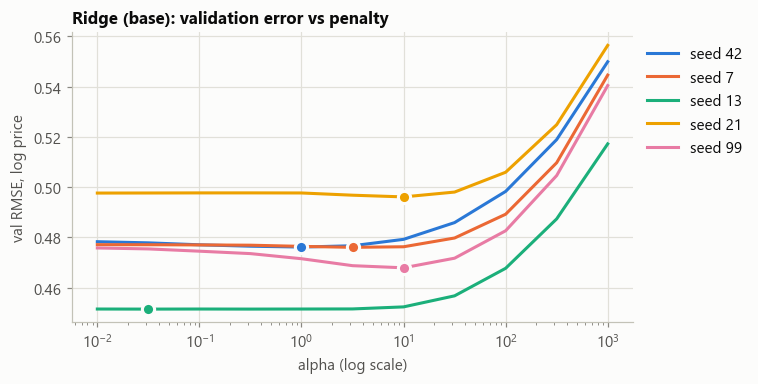

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (seed, p) in enumerate(zip(SEEDS, fitted)):
    a, r = zip(*sorted(p.val_rmse.items()))
    ax.plot(a, r, color=SERIES[i], label=f"seed {seed}")
    ax.plot(p.alpha, p.val_rmse[p.alpha], "o", ms=8, color=SERIES[i], mec=SURFACE, mew=2, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("val RMSE, log price")
ax.set_title("Ridge (base): validation error vs penalty")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### Typical % miss by property type (test MdAPE, mean over seeds)

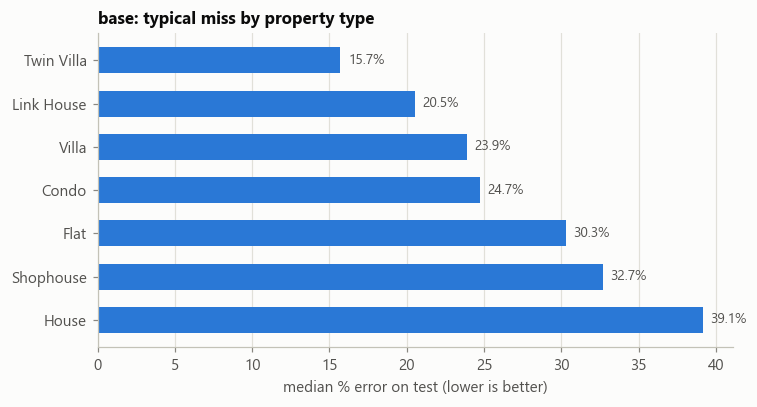

In [7]:
import json
summary = json.load(open(OUT / RUNS[0] / "summary.json"))["test"]
bt = pd.Series({t: m["median_ape"]["mean"] for t, m in summary.items() if t != "overall"}).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.4 * len(bt) + 1))
ax.barh(bt.index, bt, color=SERIES[0], height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(bt):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("median % error on test (lower is better)")
ax.set_title(f"{RUNS[0]}: typical miss by property type")
plt.tight_layout()
plt.show()

## What ridge learned
On log price, a coefficient `b` on a 0/1 flag means "price × e^b when the flag is on, everything else
equal". Shown for the first seed's `base` model. Associations in listing data, not causes.

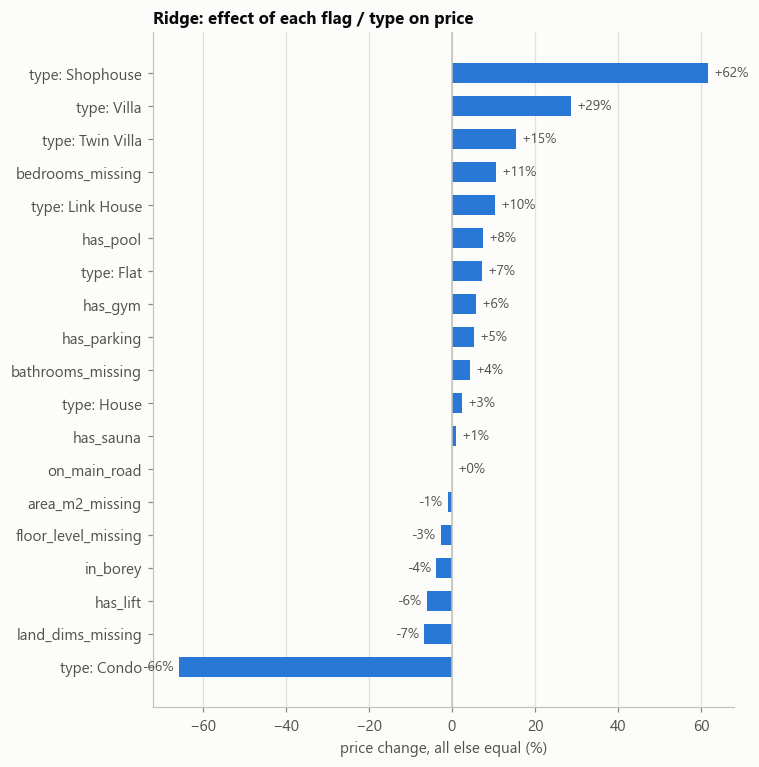

In [8]:
plot_effects(effects(fitted[0].pipe), "Ridge: effect of each flag / type on price")